DSA5206 Group Project — Reproduction of Predicting COVID-19 Pneumonia Severity on Chest X-ray With Deep Learning. 
This notebook adapts the publicly released implementation to reproduce Table 1 and Figures 2–4. It uses 94 scored chest X-rays for quantitative evaluation and 208 available images for the approximate reproduction of Figure 3.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#导入python库

import os,sys
sys.path.insert(0,"..")
sys.path.insert(0,"../..")
from glob import glob
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import sys
import torch.nn.functional as F
import pandas as pd

In [3]:
#导入torchxrayvision库

import torchxrayvision as xrv

d:\tablefiles\课程材料\DSA5206\Group Project Duong\.venv\Lib\site-packages\torchxrayvision\utils.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [4]:
#预训练densenet模型

nn_model = xrv.models.DenseNet(weights="all")#.cuda()
nn_model.op_threshs = None # to prevent sigmoid

In [5]:
#图像中心裁剪、缩放：224×224

import torchvision, torchvision.transforms
transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])

In [6]:
#加载胸片数据库

dmerge = xrv.datasets.COVID19_Dataset(
    imgpath=r"D:\tablefiles\课程材料\DSA5206\Group Project Duong\covid-chestxray-dataset-master\covid-chestxray-dataset-master\images",
    csvpath=r"D:\tablefiles\课程材料\DSA5206\Group Project Duong\covid-chestxray-dataset-master\covid-chestxray-dataset-master\metadata_2020.csv",
    transform=transform,
    views=["PA"]
)


In [7]:
#读取专家评分

scores = pd.read_csv("covid-severity-scores.csv", skiprows=5)
scores = scores.set_index("filename")

In [8]:
#展示score表格

scores

,geographic_mean,opacity_mean
filename,,
01E392EE-69F9-4E33-BFCE-E5C968654078.jpeg,6.0,4.0
03BF7561-A9BA-4C3C-B8A0-D3E585F73F3C.jpeg,2.7,2.0
1-s2.0-S0140673620303706-fx1_lrg.jpg,2.0,2.0
1-s2.0-S1684118220300608-main.pdf-001.jpg,3.7,3.0
1-s2.0-S1684118220300608-main.pdf-002.jpg,1.7,1.7
...,...,...
ryct.2020200028.fig1a.jpeg,2.0,1.7
ryct.2020200034.fig2.jpeg,1.3,1.3
ryct.2020200034.fig5-day0.jpeg,3.7,3.3


In [9]:
#合并标签

dmerge.csv = dmerge.csv.set_index("filename").join(scores, on="filename").reset_index()

In [10]:
#匹配验证

print("Total images:", len(dmerge))
print("Scored images:", dmerge.csv["geographic_mean"].notna().sum())
print("Opacity labels:", dmerge.csv["opacity_mean"].notna().sum())
print("Unique scored patients:",
      dmerge.csv.loc[dmerge.csv["geographic_mean"].notna(), "patientid"].nunique())

Total images: 208
Scored images: 94
Opacity labels: 94
Unique scored patients: 65


In [11]:
#导入Torch库，为胸片创建d1

import torch

dl = torch.utils.data.DataLoader(
    dmerge,
    batch_size=8,
    num_workers=0,
    pin_memory=False
)

In [12]:
#补充的单张图片测试

nn_model.eval()

sample = dmerge[0]["img"]
print("Image shape:", sample.shape)

with torch.no_grad():
    x = torch.from_numpy(sample).unsqueeze(0).float()
    prediction = nn_model(x)

print("Prediction shape:", prediction.shape)
print("Prediction:", prediction)

Image shape: (1, 224, 224)
Prediction shape: torch.Size([1, 18])
Prediction: tensor([[-1.9955, -2.2508, -2.3196, -3.4282, -8.0064, -6.8773, -4.0312, -1.6727,
         -5.2187, -3.4041, -4.6618, -2.7778, -0.1582, -5.6964, -6.1344, -3.5300,
         -0.8643, -2.1816]])


In [13]:
#检查缺失图片和评分情况

import os
import pandas as pd

# 查看全部208条记录对应的图片是否存在
dmerge.csv["file_exists"] = dmerge.csv["filename"].apply(
    lambda filename: os.path.isfile(
        os.path.join(dmerge.imgpath, filename)
    )
)

missing_images = dmerge.csv.loc[
    ~dmerge.csv["file_exists"],
    ["filename"]
]

print("Total records:", len(dmerge.csv))
print("Existing images:", dmerge.csv["file_exists"].sum())
print("Missing images:", len(missing_images))

print("\nMissing filenames:")
print(missing_images.to_string(index=False))

# 检查缺失图片是否有原论文评分
scored_col = "geographic_mean"

print("\nMissing images with severity scores:",
      dmerge.csv.loc[
          ~dmerge.csv["file_exists"],
          scored_col
      ].notna().sum())


Total records: 208
Existing images: 208
Missing images: 0

Missing filenames:
Empty DataFrame
Columns: [filename]
Index: []

Missing images with severity scores: 0


In [14]:
#提取94张胸片的1024维和18维特征

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# 1. 找到94张有评分的图像
scored_mask = (
    dmerge.csv["geographic_mean"].notna()
    & dmerge.csv["opacity_mean"].notna()
)

scored_indices = np.flatnonzero(scored_mask.to_numpy())

print("Scored images:", len(scored_indices))

# 2. 检查这些图像是否全部存在
for idx in scored_indices:
    filename = dmerge.csv.iloc[idx]["filename"]
    filepath = os.path.join(dmerge.imgpath, filename)
    assert os.path.isfile(filepath), f"Missing: {filename}"

assert len(scored_indices) == 94
print("All 94 scored images are available!")

# 3. 保存与特征一一对应的标签和患者信息
scored_metadata = (
    dmerge.csv.iloc[scored_indices].copy().reset_index(drop=True)
)

# 4. 只加载94张带评分图像
scored_dataset = torch.utils.data.Subset(
    dmerge, scored_indices.tolist()
)

scored_dl = torch.utils.data.DataLoader(
    scored_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# 5. 提取特征
nn_model.eval()

d_feats = []
d_preds = []

with torch.no_grad():
    for i, batch in enumerate(scored_dl):
        imgs = batch["img"]

        features = nn_model.features(imgs)
        features = F.relu(features, inplace=False)
        features = F.adaptive_avg_pool2d(features, (1, 1))

        predictions = nn_model(imgs)

        d_feats.append(features.cpu().numpy())
        d_preds.append(predictions.cpu().numpy())

        print(f"Batch {i+1}/{len(scored_dl)} completed")

# 6. 合并结果
d_feats = np.concatenate(d_feats).reshape(-1, 1024)
d_preds = np.concatenate(d_preds)

print("\nFeature extraction completed!")
print("d_feats shape:", d_feats.shape)
print("d_preds shape:", d_preds.shape)

# 7. 保存特征和对应标签
assert len(scored_metadata) == len(d_feats) == len(d_preds)

np.save("duong_d_feats_94.npy", d_feats)
np.save("duong_d_preds_94.npy", d_preds)
scored_metadata.to_csv(
    "duong_scored_metadata_94.csv",
    index=False
)

print("All files saved successfully!")



Scored images: 94
All 94 scored images are available!
Batch 1/12 completed
Batch 2/12 completed
Batch 3/12 completed
Batch 4/12 completed
Batch 5/12 completed
Batch 6/12 completed
Batch 7/12 completed
Batch 8/12 completed
Batch 9/12 completed
Batch 10/12 completed
Batch 11/12 completed
Batch 12/12 completed

Feature extraction completed!
d_feats shape: (94, 1024)
d_preds shape: (94, 18)
All files saved successfully!


In [15]:
#评估函数evaluate

import sklearn, sklearn.linear_model, sklearn.metrics, sklearn.model_selection
import scipy, scipy.stats
def evaluate(data, labels, title, plot=True, groups=None, seed=0, method="mse", target_str=""):
    X = data
    y = labels.astype(float)
    
    gss = sklearn.model_selection.GroupShuffleSplit(train_size=0.5,test_size=0.5, random_state=seed)
    train_inds, test_inds = next(gss.split(X, y, groups))
    X_train, X_test, y_train, y_test = X[train_inds], X[test_inds], y.iloc[train_inds], y.iloc[test_inds]
    #print("X_train", X_train.shape, "X_test", X_test.shape)

    if method=="mse":
        model = sklearn.linear_model.LinearRegression()
    elif method=="huber":
        model = sklearn.linear_model.HuberRegressor()
    elif method=="mae":
        # loss = max(0, |y - p| - epsilon)
        model = sklearn.linear_model.SGDRegressor(loss="epsilon_insensitive", epsilon=0, l1_ratio=1, random_state=seed)
    
    model = model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    pdiff = y_test - y_pred
    
    res = {}
    res["name"] = title
    res["R^2"] = sklearn.metrics.r2_score(y_test, y_pred)
    res["Correlation"] = scipy.stats.pearsonr(y_pred,y_test)[0]
    res["< 0.7 ACC"] = ((y_pred - y_test) < 0.7).sum()/len(y_test)
    res["explained_variance"] = sklearn.metrics.explained_variance_score(y_test, y_pred)
    res["MAE"] = sklearn.metrics.mean_absolute_error(y_test, y_pred)
    res["MSE"] = sklearn.metrics.mean_squared_error(y_test, y_pred)
    res["method"] = method
    res["# params"] = "{}+1".format(model.coef_.shape[0])

    
    if plot:
        fig, ax = plt.subplots(figsize=(6,4), dpi=100)
        for x,y,yp in zip(y_test,y_test,y_pred):
            plt.plot((x,x),(y,yp),color='red',marker='')

        pmax = int(np.max([y_pred.max(), y_test.max()]))+2
        plt.plot(range(pmax),range(pmax), c="gray", linestyle="--")
        plt.xlim(0,pmax-1)
        plt.ylim(0,pmax-1)

        plt.scatter(y_test, y_pred);
        plt.ylabel("Model prediction ($y_{pred}$)")
        plt.xlabel("Ground Truth ($y_{true}$)")
        plt.title(title);
        plt.text(0.01,0.97, "$R^2$={0:0.2f}".format(res["R^2"])+ "\n"+ 
                 "Correlation={0:0.2f}".format(res["Correlation"]), ha='left', va='top', transform=ax.transAxes)

    return res#, pdiff


In [16]:
#Table 1 的代码
#2个评分任务×5种特征组合×50次随机划分=500次线性回归实验

import numpy as np
import pandas as pd
import torchxrayvision as xrv

# 确保特征、标签及患者编号一一对应
assert d_feats.shape == (94, 1024)
assert d_preds.shape == (94, 18)
assert len(scored_metadata) == 94

groups = scored_metadata["patientid"].reset_index(drop=True)

# 论文比较的5种特征组合
pathologies = xrv.datasets.default_pathologies

four_features = [
    "Lung Opacity",
    "Pneumonia",
    "Infiltration",
    "Consolidation"
]

feature_sets = {
    "Intermediate network features": d_feats,
    "No data": np.zeros((94, 1)),
    "18 outputs": d_preds,
    "4 outputs": d_preds[:, [
        pathologies.index(name) for name in four_features
    ]],
    "lung opacity output": d_preds[:, [
        pathologies.index("Lung Opacity")
    ]]
}

# 两种严重程度评分
targets = {
    "Geographic Extent": "geographic_mean",
    "Opacity": "opacity_mean"
}

results_list = []

for target_name, target_column in targets.items():

    labels = scored_metadata[target_column].astype(float).reset_index(drop=True)

    assert labels.notna().all()

    for feature_name, data in feature_sets.items():

        print(f"Running: {target_name} / {feature_name}")

        for seed in range(50):
            result = evaluate(
                data,
                labels,
                feature_name,
                plot=False,
                groups=groups,
                seed=seed,
                method="mse",
                target_str=target_name
            )

            result["Target"] = target_name
            result["Seed"] = seed
            results_list.append(result)

results = pd.DataFrame(results_list)

# 汇总50次实验的均值和标准差
summary = (
    results.groupby(["Target", "name"])[
        ["Correlation", "R^2", "MAE", "MSE"]
    ]
    .agg(["mean", "std"])
    .round(3)
)

display(summary)

# 保存实验结果
results.to_csv("duong_reproduction_500_trials.csv", index=False)
summary.to_csv("duong_reproduction_summary.csv")

print("All 500 regression fits completed!")


Running: Geographic Extent / Intermediate network features
Running: Geographic Extent / No data
Running: Geographic Extent / 18 outputs
Running: Geographic Extent / 4 outputs
Running: Geographic Extent / lung opacity output
Running: Opacity / Intermediate network features
Running: Opacity / No data
Running: Opacity / 18 outputs
Running: Opacity / 4 outputs
Running: Opacity / lung opacity output


Correlation           R^2  \
                                                       mean    std   mean   
Target            name                                                      
Geographic Extent 18 outputs                          0.774  0.058  0.499   
                  4 outputs                           0.811  0.035  0.610   
                  Intermediate network features       0.743  0.082  0.468   
                  No data                               NaN    NaN -0.087   
                  lung opacity output                 0.808  0.036  0.604   
Opacity           18 outputs                          0.732  0.062  0.415   
                  4 outputs                           0.796  0.042  0.598   
                  Intermediate network features       0.679  0.083  0.289   
                  No data                               NaN    NaN -0.084   
                  lung opacity output                 0.793  0.040  0.592   

                                                          MAE           MSE  \
                                                   std   mean    std   mean   
Target            name                                                        
Geographic Extent 18 outputs                     0.186  1.307  0.202  2.717   
                  4 outputs                      0.074  1.172  0.116  2.118   
                  Intermediate network features  0.149  1.341  0.130  2.855   
                  No data                        0.092  2.072  0.167  5.970   
                  lung opacity output            0.077  1.161  0.102  2.145   
Opacity           18 outputs                     0.159  0.897  0.122  1.281   
                  4 outputs                      0.073  0.761  0.071  0.881   
                  Intermediate network features  0.167  1.012  0.092  1.548   
                  No data                        0.100  1.289  0.104  2.398   
                  lung opacity output            0.065  0.788  0.061  0.892   

                                                        
                                                   std  
Target            name                                  
Geographic Extent 18 outputs                     0.921  
                  4 outputs                      0.367  
                  Intermediate network features  0.596  
                  No data                        0.899  
                  lung opacity output            0.330  
Opacity           18 outputs                     0.343  
                  4 outputs                      0.150  
                  Intermediate network features  0.294  
                  No data                        0.370  
                  lung opacity output            0.124

All 500 regression fits completed!


In [17]:
#Table 1的对比表格

import pandas as pd
from IPython.display import display

# 1. 读取已经保存的500次实验结果
results_saved = pd.read_csv(
    "duong_reproduction_500_trials.csv"
)

# 2. 计算我们的均值和标准差
metrics = ["Correlation", "R^2", "MAE", "MSE"]

ours = (
    results_saved.groupby(["Target", "name"])[metrics]
    .agg(["mean", "std"])
)

# 3. 原论文Table 1中的数据
# 格式：(Target, name, Correlation, R2, MAE, MSE)
paper_data = [
    ("Geographic Extent", "lung opacity output",
     "0.80±0.05", "0.60±0.09", "1.14±0.11", "2.06±0.34"),
    ("Geographic Extent", "4 outputs",
     "0.79±0.05", "0.57±0.10", "1.19±0.11", "2.17±0.37"),
    ("Geographic Extent", "18 outputs",
     "0.76±0.08", "0.47±0.16", "1.32±0.17", "2.73±0.89"),
    ("Geographic Extent", "Intermediate network features",
     "0.74±0.08", "0.43±0.16", "1.36±0.13", "2.88±0.58"),
    ("Geographic Extent", "No data",
     "0.00±0.00", "-0.08±0.10", "2.00±0.17", "5.60±0.95"),

    ("Opacity", "lung opacity output",
     "0.78±0.04", "0.58±0.09", "0.78±0.05", "0.86±0.11"),
    ("Opacity", "4 outputs",
     "0.78±0.04", "0.58±0.09", "0.76±0.05", "0.87±0.12"),
    ("Opacity", "18 outputs",
     "0.73±0.09", "0.44±0.16", "0.86±0.11", "1.15±0.33"),
    ("Opacity", "Intermediate network features",
     "0.66±0.08", "0.25±0.21", "1.01±0.09", "1.54±0.28"),
    ("Opacity", "No data",
     "0.00±0.00", "-0.08±0.10", "1.24±0.10", "2.26±0.36")
]

paper_columns = [
    "Task", "Features", "Correlation",
    "R2", "MAE", "MSE"
]

paper = pd.DataFrame(paper_data, columns=paper_columns)

# 4. 生成与原论文并排的比较表
rows = []

for _, p in paper.iterrows():
    key = (p["Task"], p["Features"])

    row = {
        "Task": p["Task"],
        "Features": p["Features"]
    }

    for metric in metrics:
        paper_col = "R2" if metric == "R^2" else metric

        mean = ours.loc[key, (metric, "mean")]
        std = ours.loc[key, (metric, "std")]

        row[f"{paper_col} (Paper)"] = p[paper_col]

        row[f"{paper_col} (Ours)"] = (
            f"{mean:.3f}±{std:.3f}"
            if pd.notna(mean) and pd.notna(std)
            else "N/A"
        )

    rows.append(row)

comparison = pd.DataFrame(rows)


# 5. 按照原论文 Table 1 的顺序排列实验结果

task_order = [
    "Opacity",
    "Geographic Extent"
]

feature_order = [
    "lung opacity output",
    "4 outputs",
    "18 outputs",
    "Intermediate network features",
    "No data"
]

comparison["Task"] = pd.Categorical(
    comparison["Task"],
    categories=task_order,
    ordered=True
)

comparison["Features"] = pd.Categorical(
    comparison["Features"],
    categories=feature_order,
    ordered=True
)

comparison = (
    comparison
    .sort_values(["Task", "Features"])
    .reset_index(drop=True)
)

# 6. 恢复普通字符串列，便于保存和展示
comparison["Task"] = comparison["Task"].astype(str)
comparison["Features"] = comparison["Features"].astype(str)


# 7. 显示完整对比表
display(comparison)

# 8. 保存CSV和HTML
comparison.to_csv(
    "Duong_Table1_Comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison.to_html(
    "Duong_Table1_Comparison.html",
    index=False
)

print("Comparison table saved successfully!")


,Task,Features,Correlation (Paper),Correlation (Ours),R2 (Paper),R2 (Ours),MAE (Paper),MAE (Ours),MSE (Paper),MSE (Ours)
0,Opacity,lung opacity output,0.78±0.04,0.793±0.040,0.58±0.09,0.592±0.065,0.78±0.05,0.788±0.061,0.86±0.11,0.892±0.124
1,Opacity,4 outputs,0.78±0.04,0.796±0.042,0.58±0.09,0.598±0.073,0.76±0.05,0.761±0.071,0.87±0.12,0.881±0.150
2,Opacity,18 outputs,0.73±0.09,0.732±0.062,0.44±0.16,0.415±0.159,0.86±0.11,0.897±0.122,1.15±0.33,1.281±0.343
3,Opacity,Intermediate network features,0.66±0.08,0.679±0.083,0.25±0.21,0.289±0.167,1.01±0.09,1.012±0.092,1.54±0.28,1.548±0.294
4,Opacity,No data,0.00±0.00,N/A,-0.08±0.10,-0.084±0.100,1.24±0.10,1.289±0.104,2.26±0.36,2.398±0.370
5,Geographic Extent,lung opacity output,0.80±0.05,0.808±0.036,0.60±0.09,0.604±0.077,1.14±0.11,1.161±0.102,2.06±0.34,2.145±0.330
6,Geographic Extent,4 outputs,0.79±0.05,0.811±0.035,0.57±0.10,0.610±0.074,1.19±0.11,1.172±0.116,2.17±0.37,2.118±0.367
7,Geographic Extent,18 outputs,0.76±0.08,0.774±0.058,0.47±0.16,0.499±0.186,1.32±0.17,1.307±0.202,2.73±0.89,2.717±0.921
8,Geographic Extent,Intermediate network features,0.74±0.08,0.743±0.082,0.43±0.16,0.468±0.149,1.36±0.13,1.341±0.130,2.88±0.58,2.855±0.596
9,Geographic Extent,No data,0.00±0.00,N/A,-0.08±0.10,-0.087±0.092,2.00±0.17,2.072±0.167,5.60±0.95,5.970±0.899


Comparison table saved successfully!


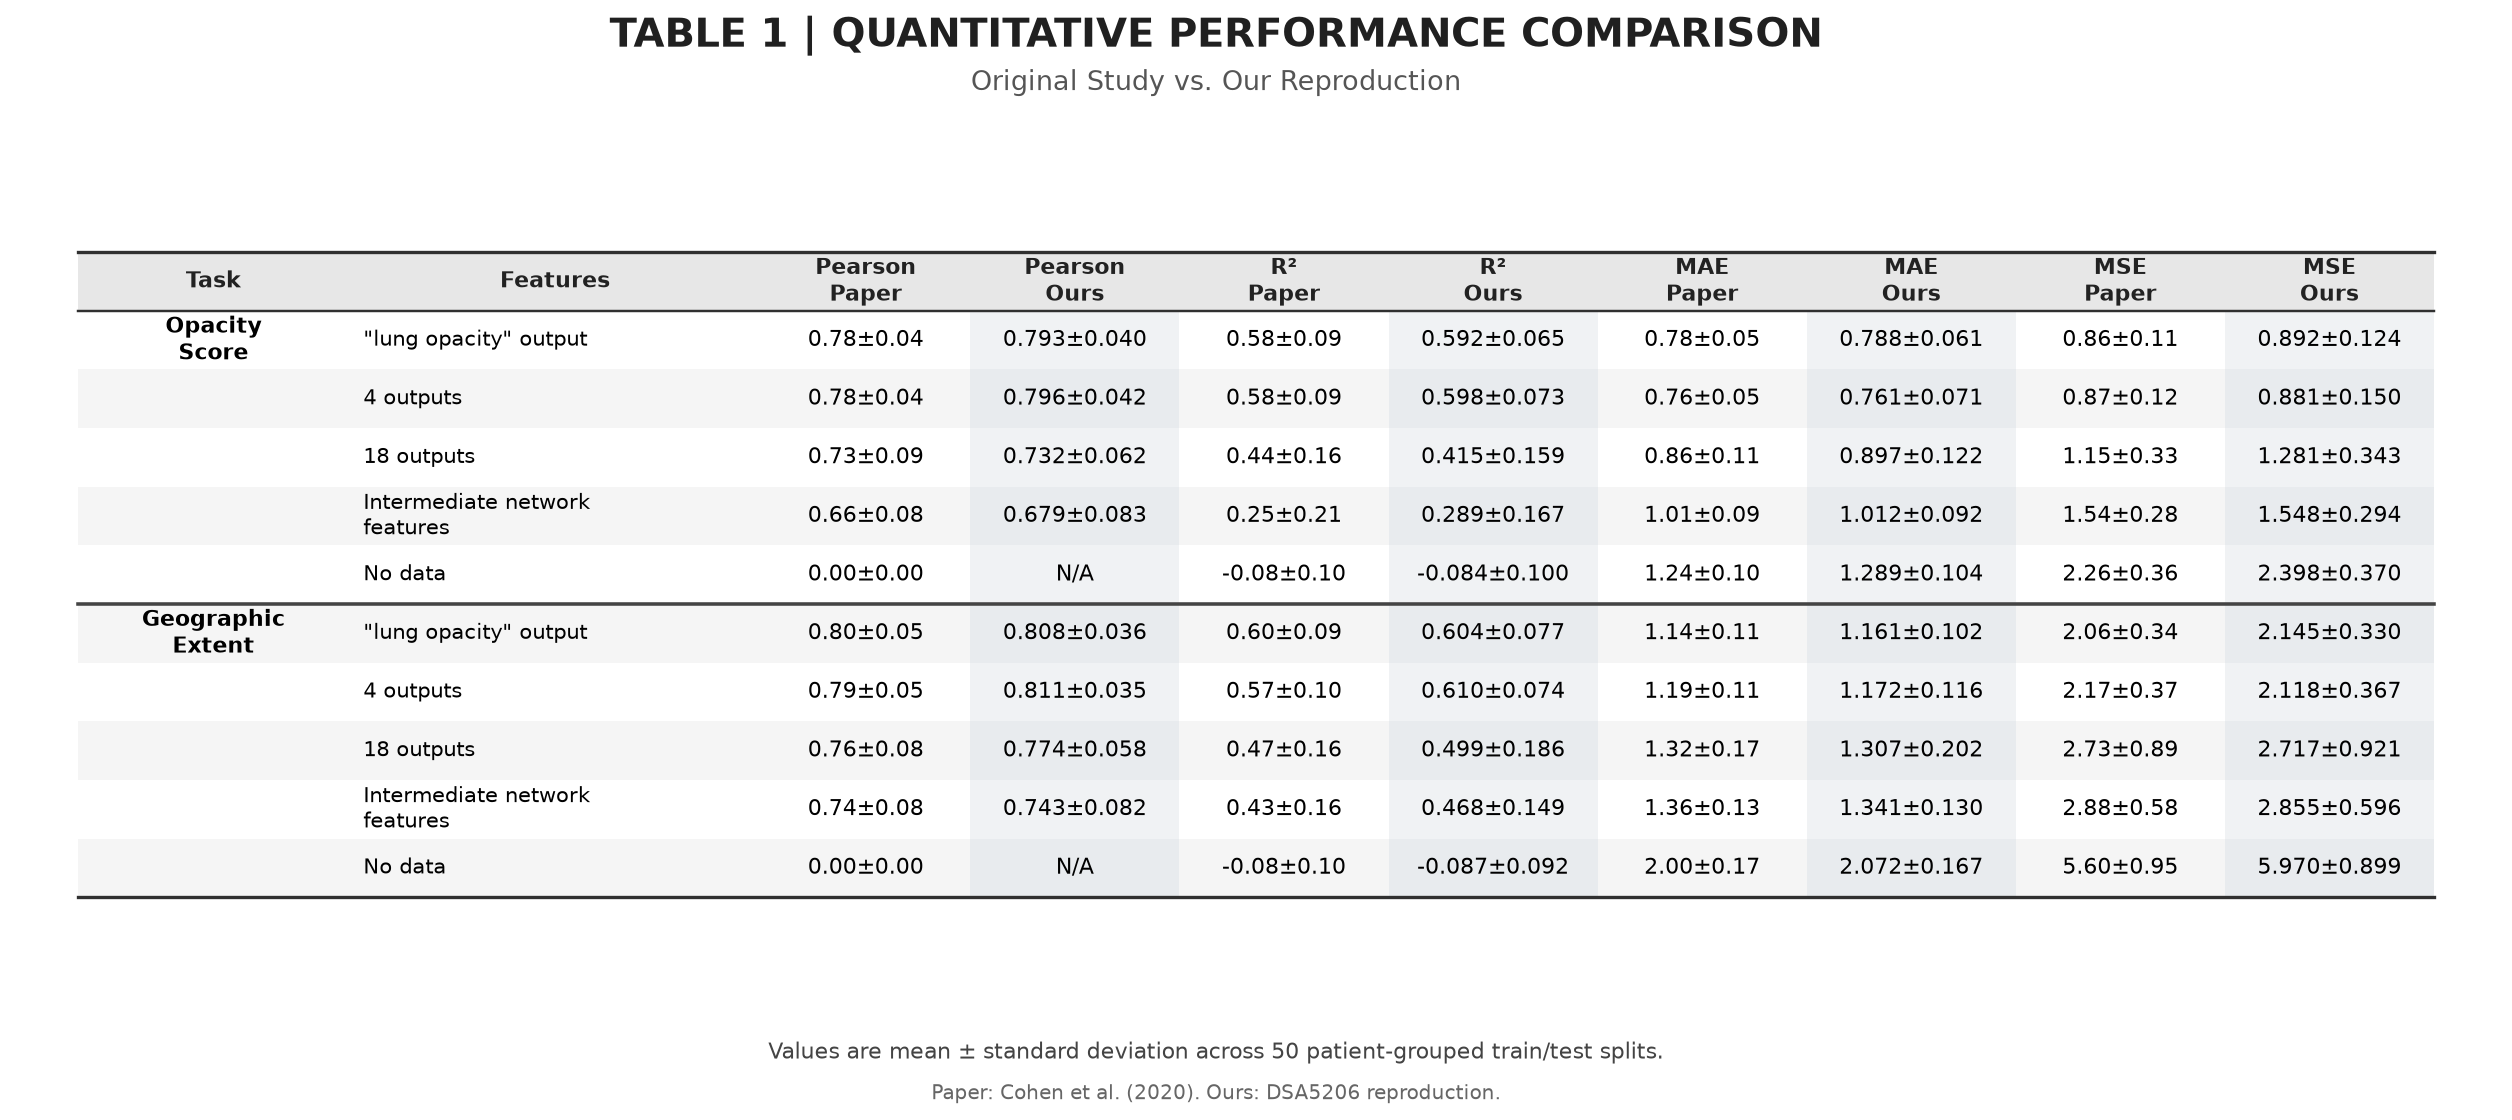

Final Table 1 saved successfully!


In [18]:
#Table 1的对比表格导出为图片


import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 使用已经排好顺序的 comparison 数据表
assert len(comparison) == 10

# 更接近原论文的英文特征名称
feature_labels = {
    "lung opacity output": '"lung opacity" output',
    "4 outputs": "4 outputs",
    "18 outputs": "18 outputs",
    "Intermediate network features": "Intermediate network\nfeatures",
    "No data": "No data"
}

# 两组任务各5行
display_df = comparison.copy()

display_df["Features"] = display_df["Features"].map(
    feature_labels
)

display_df["Task"] = (
    ["Opacity\nScore"] + [""] * 4
    + ["Geographic\nExtent"] + [""] * 4
)

# 保持两组任务顺序
columns = [
    "Task", "Features",
    "Correlation (Paper)", "Correlation (Ours)",
    "R2 (Paper)", "R2 (Ours)",
    "MAE (Paper)", "MAE (Ours)",
    "MSE (Paper)", "MSE (Ours)"
]

display_df = display_df[columns]

# 构建高分辨率图表
fig, ax = plt.subplots(figsize=(20, 7.7), dpi=160)
ax.axis("off")

fig.patch.set_facecolor("white")

# 标题
fig.text(
    0.5, 0.94,
    "TABLE 1 | QUANTITATIVE PERFORMANCE COMPARISON",
    ha="center", va="center",
    fontsize=18, fontweight="bold",
    color="#202020"
)

fig.text(
    0.5, 0.902,
    "Original Study vs. Our Reproduction",
    ha="center", va="center",
    fontsize=12, color="#555555"
)

headers = [
    "Task", "Features",
    "Pearson\nPaper", "Pearson\nOurs",
    "R²\nPaper", "R²\nOurs",
    "MAE\nPaper", "MAE\nOurs",
    "MSE\nPaper", "MSE\nOurs"
]

# 将表格限制在画布内
bbox = [0.025, 0.17, 0.95, 0.68]

table = ax.table(
    cellText=display_df.values,
    colLabels=headers,
    cellLoc="center",
    colLoc="center",
    bbox=bbox
)

table.auto_set_font_size(False)
table.set_fontsize(10)

# 列宽比例（合计1）
widths = [
    0.115, 0.175,
    0.08875, 0.08875,
    0.08875, 0.08875,
    0.08875, 0.08875,
    0.08875, 0.08875
]

n_rows = len(display_df) + 1
n_cols = len(headers)

for (r, c), cell in table.get_celld().items():

    cell.set_width(bbox[2] * widths[c])

    # 减少网格线，让表格更接近学术论文
    cell.set_linewidth(0)
    cell.PAD = 0.035

    if r == 0:
        cell.set_facecolor("#E7E7E7")
        cell.set_text_props(
            weight="bold",
            color="#222222",
            fontsize=10
        )
    else:
        cell.set_facecolor(
            "#FFFFFF" if r % 2 else "#F5F5F5"
        )

        if c == 1:
            cell.set_text_props(
                ha="left",
                fontsize=9.5
            )

        # 将首行的任务名称加粗
        if c == 0 and r in (1, 6):
            cell.set_text_props(
                weight="bold",
                fontsize=10
            )

        # Paper与Ours使用细微背景区别
        if c in (3, 5, 7, 9):
            cell.set_facecolor(
                "#F0F2F4" if r % 2 else "#E8EBEE"
            )

# 顶部、表头下方和底部横线
x0 = bbox[0]
x1 = bbox[0] + bbox[2]

y_bottom = bbox[1]
y_top = bbox[1] + bbox[3]

row_height = bbox[3] / n_rows

for y, lw in [
    (y_top, 1.5),
    (y_top - row_height, 1.1),
    (y_bottom, 1.5)
]:
    ax.plot(
        [x0, x1], [y, y],
        transform=ax.transAxes,
        color="#303030",
        linewidth=lw
    )

# Opacity与Geographic Extent之间的分隔线
separator_y = y_top - row_height * 6

ax.plot(
    [x0, x1],
    [separator_y, separator_y],
    transform=ax.transAxes,
    color="#444444",
    linewidth=1.6
)

# 脚注
fig.text(
    0.5, 0.11,
    "Values are mean ± standard deviation across 50 "
    "patient-grouped train/test splits.",
    ha="center",
    fontsize=10,
    color="#444444"
)

fig.text(
    0.5, 0.077,
    "Paper: Cohen et al. (2020). "
    "Ours: DSA5206 reproduction.",
    ha="center",
    fontsize=9,
    color="#666666"
)


# 保存最终版本的Table 1
plt.savefig(
    "Duong_Table1_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Duong_Table1_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Final Table 1 saved successfully!")


Training images: 47
Testing images: 47
Geographic Extent: R²=0.673, Correlation=0.837
Opacity Score: R²=0.646, Correlation=0.808


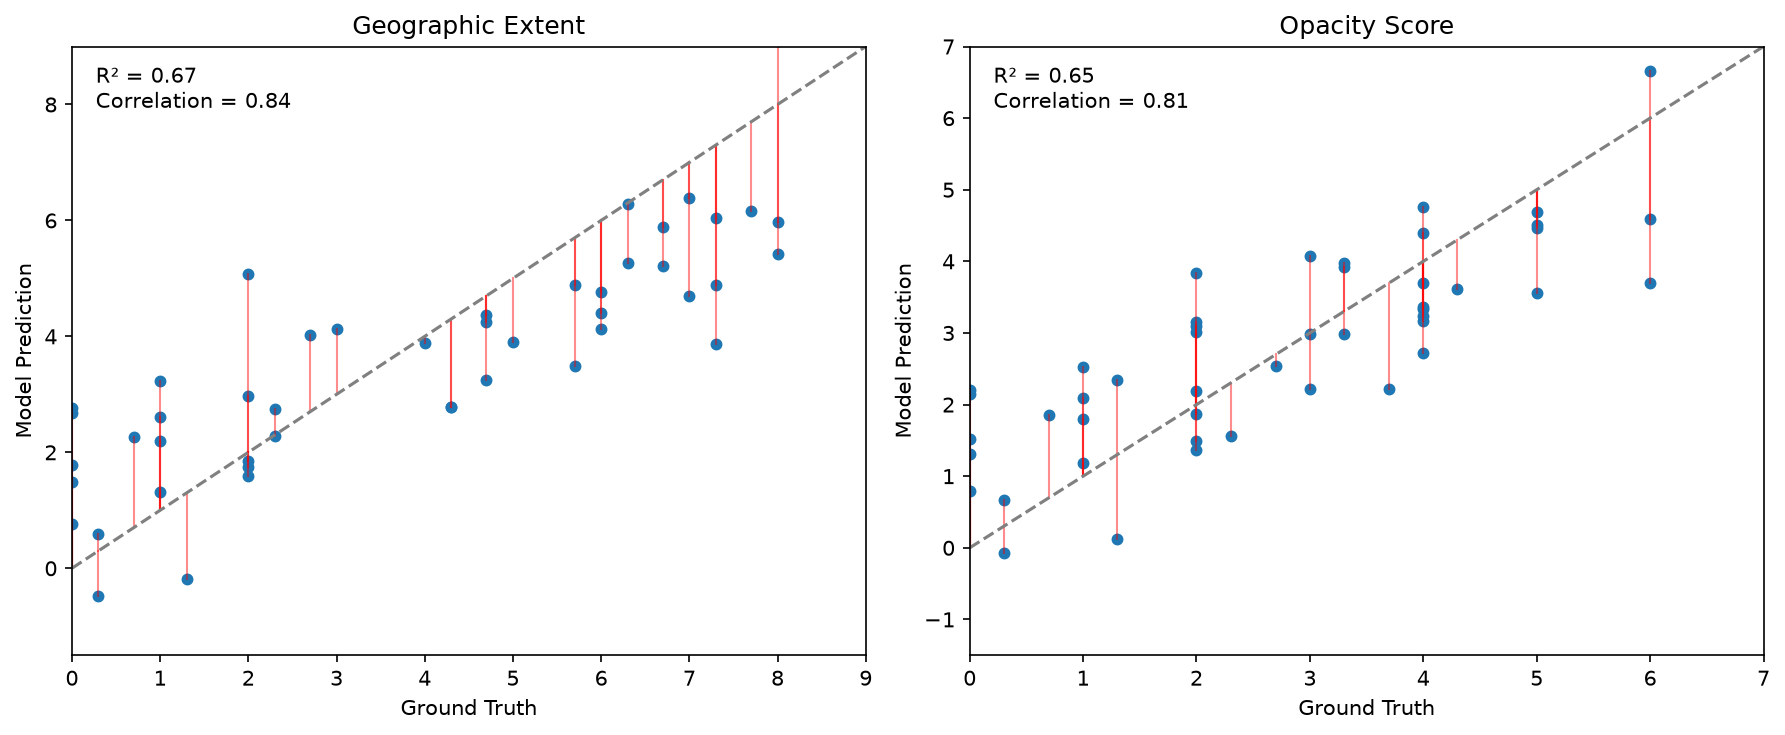

Figure 2 reproduction saved successfully!


In [19]:
#Figure 2 的代码

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy.stats import pearsonr

# 1. 读取之前保存的94张胸片数据
d_preds = np.load("duong_d_preds_94.npy")
metadata = pd.read_csv("duong_scored_metadata_94.csv")

assert d_preds.shape == (94, 18)
assert len(metadata) == 94

# 2. 选择论文最优方案使用的 Lung Opacity 特征
feature_idx = xrv.datasets.default_pathologies.index(
    "Lung Opacity"
)

X = d_preds[:, [feature_idx]]
groups = metadata["patientid"]

# 3. 按患者分组，50%训练、50%测试
seed = 1

splitter = GroupShuffleSplit(
    train_size=0.5,
    test_size=0.5,
    random_state=seed
)

train_idx, test_idx = next(
    splitter.split(X, groups=groups)
)

print("Training images:", len(train_idx))
print("Testing images:", len(test_idx))

# 4. 分别训练两种评分的线性回归
tasks = [
    ("geographic_mean", "Geographic Extent", 8),
    ("opacity_mean", "Opacity Score", 6)
]

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), dpi=150
)

prediction_records = []

for ax, (column, title, score_max) in zip(axes, tasks):

    y = metadata[column].astype(float).to_numpy()

    model = LinearRegression()
    model.fit(X[train_idx], y[train_idx])

    y_true = y[test_idx]
    y_pred = model.predict(X[test_idx])

    r2 = r2_score(y_true, y_pred)
    corr = pearsonr(y_true, y_pred)[0]

    # 红线：真实评分与预测评分之间的误差
    for actual, predicted in zip(y_true, y_pred):
        ax.plot(
            [actual, actual],
            [actual, predicted],
            color="red",
            alpha=0.45,
            linewidth=1
        )

    # 散点：每张测试胸片
    ax.scatter(y_true, y_pred, s=22)

    # 虚线：完美预测
    ax.plot(
        [0, score_max + 1],
        [0, score_max + 1],
        linestyle="--",
        color="gray"
    )

    ax.set_xlim(0, score_max + 1)
    ax.set_ylim(-1.5, score_max + 1)

    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Model Prediction")
    ax.set_title(title)

    ax.text(
        0.03, 0.97,
        f"R² = {r2:.2f}\nCorrelation = {corr:.2f}",
        transform=ax.transAxes,
        va="top"
    )

    # 保存每张测试图片的真实值和预测值
    for idx, actual, predicted in zip(
        test_idx, y_true, y_pred
    ):
        prediction_records.append({
            "Task": title,
            "Filename": metadata.iloc[idx]["filename"],
            "PatientID": metadata.iloc[idx]["patientid"],
            "Ground Truth": actual,
            "Prediction": predicted,
            "Error": predicted - actual
        })

    print(f"{title}: R²={r2:.3f}, Correlation={corr:.3f}")

# 5. 保存图片和预测数据
plt.tight_layout()

plt.savefig(
    "Duong_Figure2_Reproduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Duong_Figure2_Reproduction.pdf",
    bbox_inches="tight"
)

plt.show()

pd.DataFrame(prediction_records).to_csv(
    "Duong_Figure2_Predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Figure 2 reproduction saved successfully!")


In [20]:
#额外114张胸片的特征提取，总共208张特征

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

# 加载已经保存的94张胸片特征
preds_94 = np.load("duong_d_preds_94.npy")
meta_94 = pd.read_csv("duong_scored_metadata_94.csv")

# 使用原始数据表，保留所有实际存在的图片
meta_all = dmerge.csv.copy().reset_index(drop=True)

meta_all = meta_all[
    meta_all["filename"].map(
        lambda f: __import__("os").path.isfile(
            __import__("os").path.join(dmerge.imgpath, f)
        )
    )
].copy()

# 保留在原数据集中的行号
original_indices = meta_all.index.to_numpy()
meta_all = meta_all.reset_index(drop=True)

assert len(meta_all) == 208
assert meta_all["filename"].is_unique
assert meta_94["filename"].is_unique

# 根据文件名复用94张图片已经提取的特征
saved_features = dict(zip(meta_94["filename"], preds_94))

preds_all = np.zeros((len(meta_all), 18), dtype=np.float32)
missing_positions = []

for pos, filename in enumerate(meta_all["filename"]):
    if filename in saved_features:
        preds_all[pos] = saved_features[filename]
    else:
        missing_positions.append(pos)

print("Reused features:", len(meta_all) - len(missing_positions))
print("Images requiring extraction:", len(missing_positions))

# 只处理尚未提取的113张图片
extra_dataset = torch.utils.data.Subset(
    dmerge,
    original_indices[missing_positions].tolist()
)

extra_dl = torch.utils.data.DataLoader(
    extra_dataset, batch_size=8,
    shuffle=False, num_workers=0
)

nn_model.eval()
new_preds = []

with torch.no_grad():
    for i, batch in enumerate(extra_dl):
        pred = nn_model(batch["img"])
        new_preds.append(pred.cpu().numpy())
        print(f"Extra batch {i+1}/{len(extra_dl)} completed")

preds_all[missing_positions] = np.concatenate(new_preds)

assert preds_all.shape == (208, 18)

# 保存完整特征及行顺序
np.save("duong_d_preds_208.npy", preds_all)
meta_all.to_csv("duong_metadata_208.csv", index=False)

print("Full feature extraction completed!")
print("Feature shape:", preds_all.shape)


Reused features: 94
Images requiring extraction: 114
Extra batch 1/15 completed
Extra batch 2/15 completed
Extra batch 3/15 completed
Extra batch 4/15 completed
Extra batch 5/15 completed
Extra batch 6/15 completed
Extra batch 7/15 completed
Extra batch 8/15 completed
Extra batch 9/15 completed
Extra batch 10/15 completed
Extra batch 11/15 completed
Extra batch 12/15 completed
Extra batch 13/15 completed
Extra batch 14/15 completed
Extra batch 15/15 completed
Full feature extraction completed!
Feature shape: (208, 18)


scikit-learn version: 1.9.1
Feature shape: (208, 4)


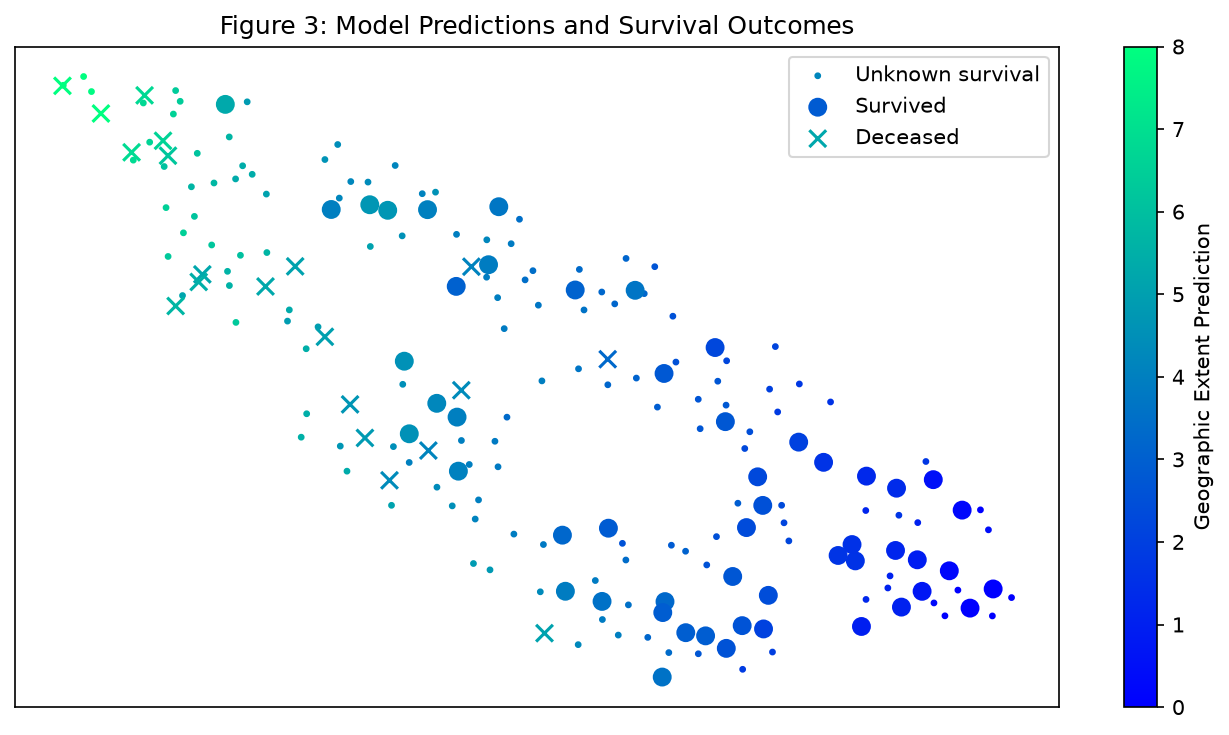

In [21]:
#Figure 3 的代码（使用 scikit-learn 的 t-SNE）

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.manifold import TSNE

preds_all = np.load("duong_d_preds_208.npy")
meta_all = pd.read_csv("duong_metadata_208.csv")

names = [
    "Lung Opacity",
    "Pneumonia",
    "Infiltration",
    "Consolidation"
]

indices = [
    xrv.datasets.default_pathologies.index(name)
    for name in names
]

X4 = preds_all[:, indices]

print("scikit-learn version:", sklearn.__version__)
print("Feature shape:", X4.shape)

# 显式设置 t-SNE 的参数，便于记录和重现
embedding = TSNE(
    n_components=2,
    random_state=54,
    perplexity=30,
    learning_rate=200,
    init="random"
).fit_transform(X4)

# 使用原作者的生存状态分类
survival = meta_all["survival"].fillna("").astype(str)

categories = {
    "Unknown survival": ~survival.isin(["Y", "N"]),
    "Survived": survival == "Y",
    "Deceased": survival == "N"
}
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

preds_94 = np.load("duong_d_preds_94.npy")
meta_94 = pd.read_csv("duong_scored_metadata_94.csv")

opacity_idx = xrv.datasets.default_pathologies.index("Lung Opacity")

# 训练单特征线性回归模型
X94 = preds_94[:, [opacity_idx]]
y94 = meta_94["geographic_mean"].astype(float).to_numpy()

splitter = GroupShuffleSplit(
    train_size=0.5,
    test_size=0.5,
    random_state=0
)

train_idx, test_idx = next(
    splitter.split(X94, y94, groups=meta_94["patientid"])
)

reg = LinearRegression()
reg.fit(X94[train_idx], y94[train_idx])

# 使用回归模型预测严重程度
predicted_geo = reg.predict(
    preds_all[:, [opacity_idx]]
)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

styles = {
    "Unknown survival": ("o", 5),
    "Survived": ("o", 65),
    "Deceased": ("x", 65)
}

for label, mask in categories.items():
    mask = mask.to_numpy()
    marker, size = styles[label]

    ax.scatter(
        embedding[mask, 0],
        embedding[mask, 1],
        c=predicted_geo[mask],
        s=size,
        marker=marker,
        cmap="winter",
        vmin=0,
        vmax=8,
        label=label
    )

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

colorbar = fig.colorbar(
    ScalarMappable(
        norm=Normalize(vmin=0, vmax=8),
        cmap="winter"
    ),
    ax=ax
)

colorbar.set_label("Geographic Extent Prediction")

ax.set_title(
    "Figure 3: Model Predictions and Survival Outcomes"
)

ax.set_xticks([])
ax.set_yticks([])
ax.legend()

plt.tight_layout()

plt.savefig(
    "Duong_Figure3_Reproduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Image shape: (1, 224, 224)
Gradient shape: (224, 224)
Maximum absolute gradient: 0.0003118165


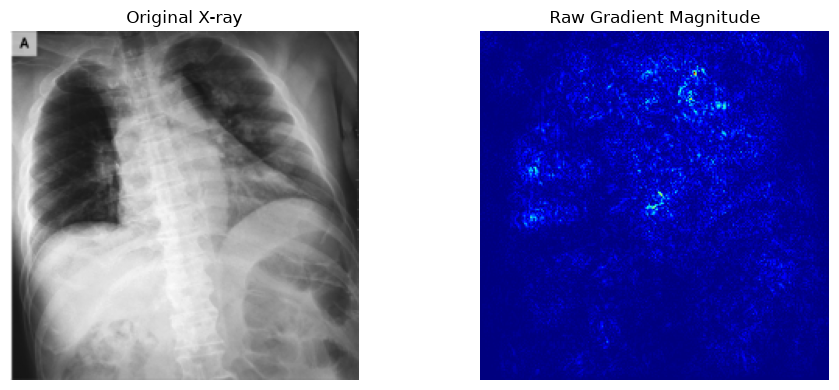

In [22]:
#梯度测试

import torch
import numpy as np
import matplotlib.pyplot as plt

# 选取第一张有评分胸片
sample = scored_dataset[0]
img = sample["img"]

# 转换为 PyTorch Tensor，开启梯度
x = torch.tensor(
    img, dtype=torch.float32
).unsqueeze(0)

x.requires_grad_(True)

# 确保模型处于评估模式
nn_model.eval()
nn_model.zero_grad()

# 提取 Lung Opacity 输出
opacity_idx = xrv.datasets.default_pathologies.index(
    "Lung Opacity"
)

output = nn_model(x)
score = output[0, opacity_idx]

# 计算输入图像梯度
score.backward()

gradient = x.grad.detach().cpu().numpy()[0, 0]

print("Image shape:", img.shape)
print("Gradient shape:", gradient.shape)
print("Maximum absolute gradient:", np.abs(gradient).max())

# 绘制原始图片和梯度图
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img[0], cmap="gray")
axes[0].set_title("Original X-ray")
axes[0].axis("off")

axes[1].imshow(np.abs(gradient), cmap="jet")
axes[1].set_title("Raw Gradient Magnitude")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Regression coefficient: 0.8749161
Regression intercept: 3.6210182


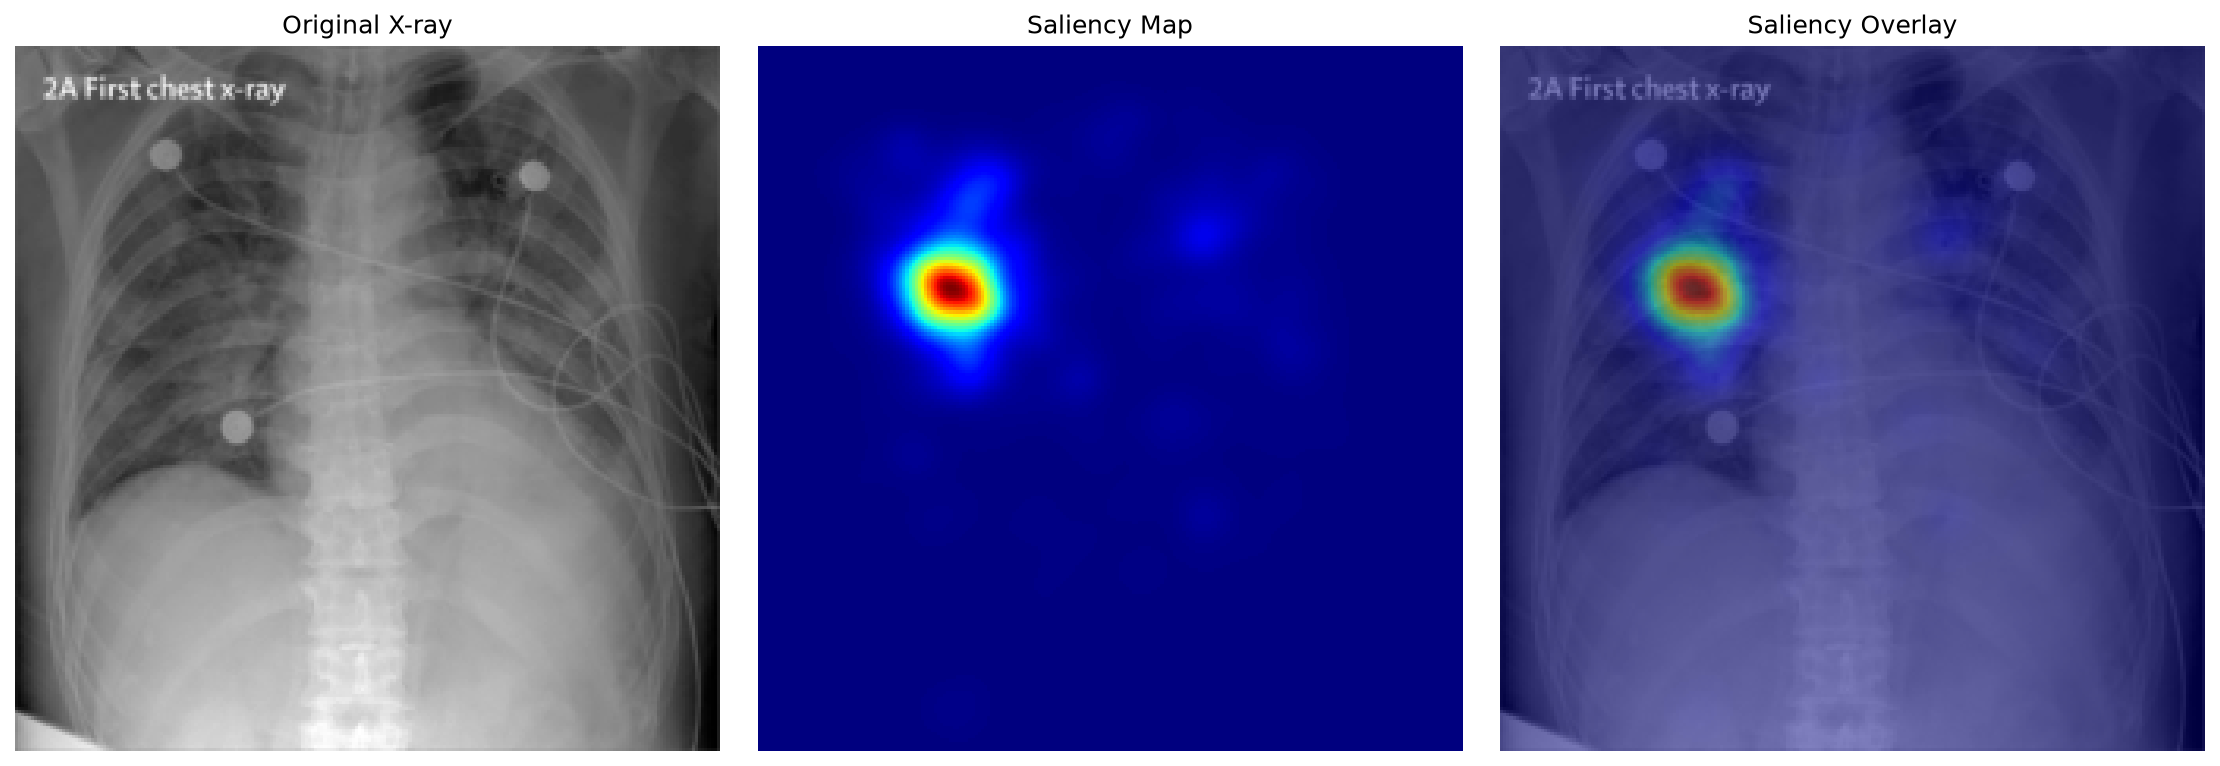

Filename: lancet-case2a.jpg
Ground Truth: 6.0
Predicted Extent: 4.951241970062256
Maximum saliency: 6.046014e-08
Saliency map saved successfully!


In [23]:
#Figure 4 前的单张测试

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

# 1. 加载之前保存的94张胸片的特征和标签
preds_94 = np.load("duong_d_preds_94.npy")
meta_94 = pd.read_csv("duong_scored_metadata_94.csv")

opacity_idx = xrv.datasets.default_pathologies.index(
    "Lung Opacity"
)

X = preds_94[:, [opacity_idx]]
y = meta_94["geographic_mean"].astype(float).to_numpy()
groups = meta_94["patientid"]

# 2. 按患者分组，训练一次线性回归
splitter = GroupShuffleSplit(
    train_size=0.5,
    test_size=0.5,
    random_state=0
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

geo_model = LinearRegression()
geo_model.fit(X[train_idx], y[train_idx])

print("Regression coefficient:", geo_model.coef_[0])
print("Regression intercept:", geo_model.intercept_)

# 3. 确保使用之前加载的预训练DenseNet
nn_model.eval()

# 4. 选择一张未参与回归训练的测试图像
idx = int(test_idx[0])

# scored_dataset 的顺序与 meta_94 一致
sample = scored_dataset[idx]
img = sample["img"]

x = torch.as_tensor(
    img, dtype=torch.float32
).unsqueeze(0).clone().detach()

x.requires_grad_(True)

# 5. DenseNet输出 + 线性回归
nn_model.zero_grad()

outputs = nn_model(x)
lung_opacity = outputs[:, opacity_idx]

theta = float(geo_model.coef_[0])
bias = float(geo_model.intercept_)

predicted_extent = theta * lung_opacity + bias

# 6. 计算最终评分对输入图像的梯度
grads = torch.autograd.grad(
    predicted_extent.sum(), x
)[0][0, 0].detach().cpu().numpy()

# 7. 按照原作者代码：梯度平方 + Gaussian平滑
saliency = gaussian(
    grads**2,
    sigma=(5, 5),
    truncate=3.5
)

# 8. 可视化
original = img[0]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), dpi=150
)

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original X-ray")
axes[0].axis("off")

axes[1].imshow(saliency, cmap="jet")
axes[1].set_title("Saliency Map")
axes[1].axis("off")

axes[2].imshow(original, cmap="gray")
axes[2].imshow(
    saliency,
    cmap="jet",
    alpha=0.5,
    vmin=0,
    vmax=saliency.max()
)
axes[2].set_title("Saliency Overlay")
axes[2].axis("off")

plt.tight_layout()

plt.savefig(
    "Duong_Figure4_Saliency_Test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Filename:", meta_94.iloc[idx]["filename"])
print("Ground Truth:", y[idx])
print("Predicted Extent:", predicted_extent.item())
print("Maximum saliency:", saliency.max())
print("Saliency map saved successfully!")


Test set size: 47


,Case,filename,ground_truth,prediction,error
0,(a) relatively correct / severe,ryct.2020200034.fig5-day7.jpeg,4.3,4.323956,0.023956
1,(b) relatively correct / mild,nCoV-radiol.2020200269.fig1-day7.jpeg,0.7,0.481065,-0.218935
2,(c) overestimation,ciaa199.pdf-001-a.png,0.0,2.692539,2.692539
3,(d) underestimation,covid-19-pneumonia-rapidly-progressive-12-hour...,7.3,3.931380,-3.368620


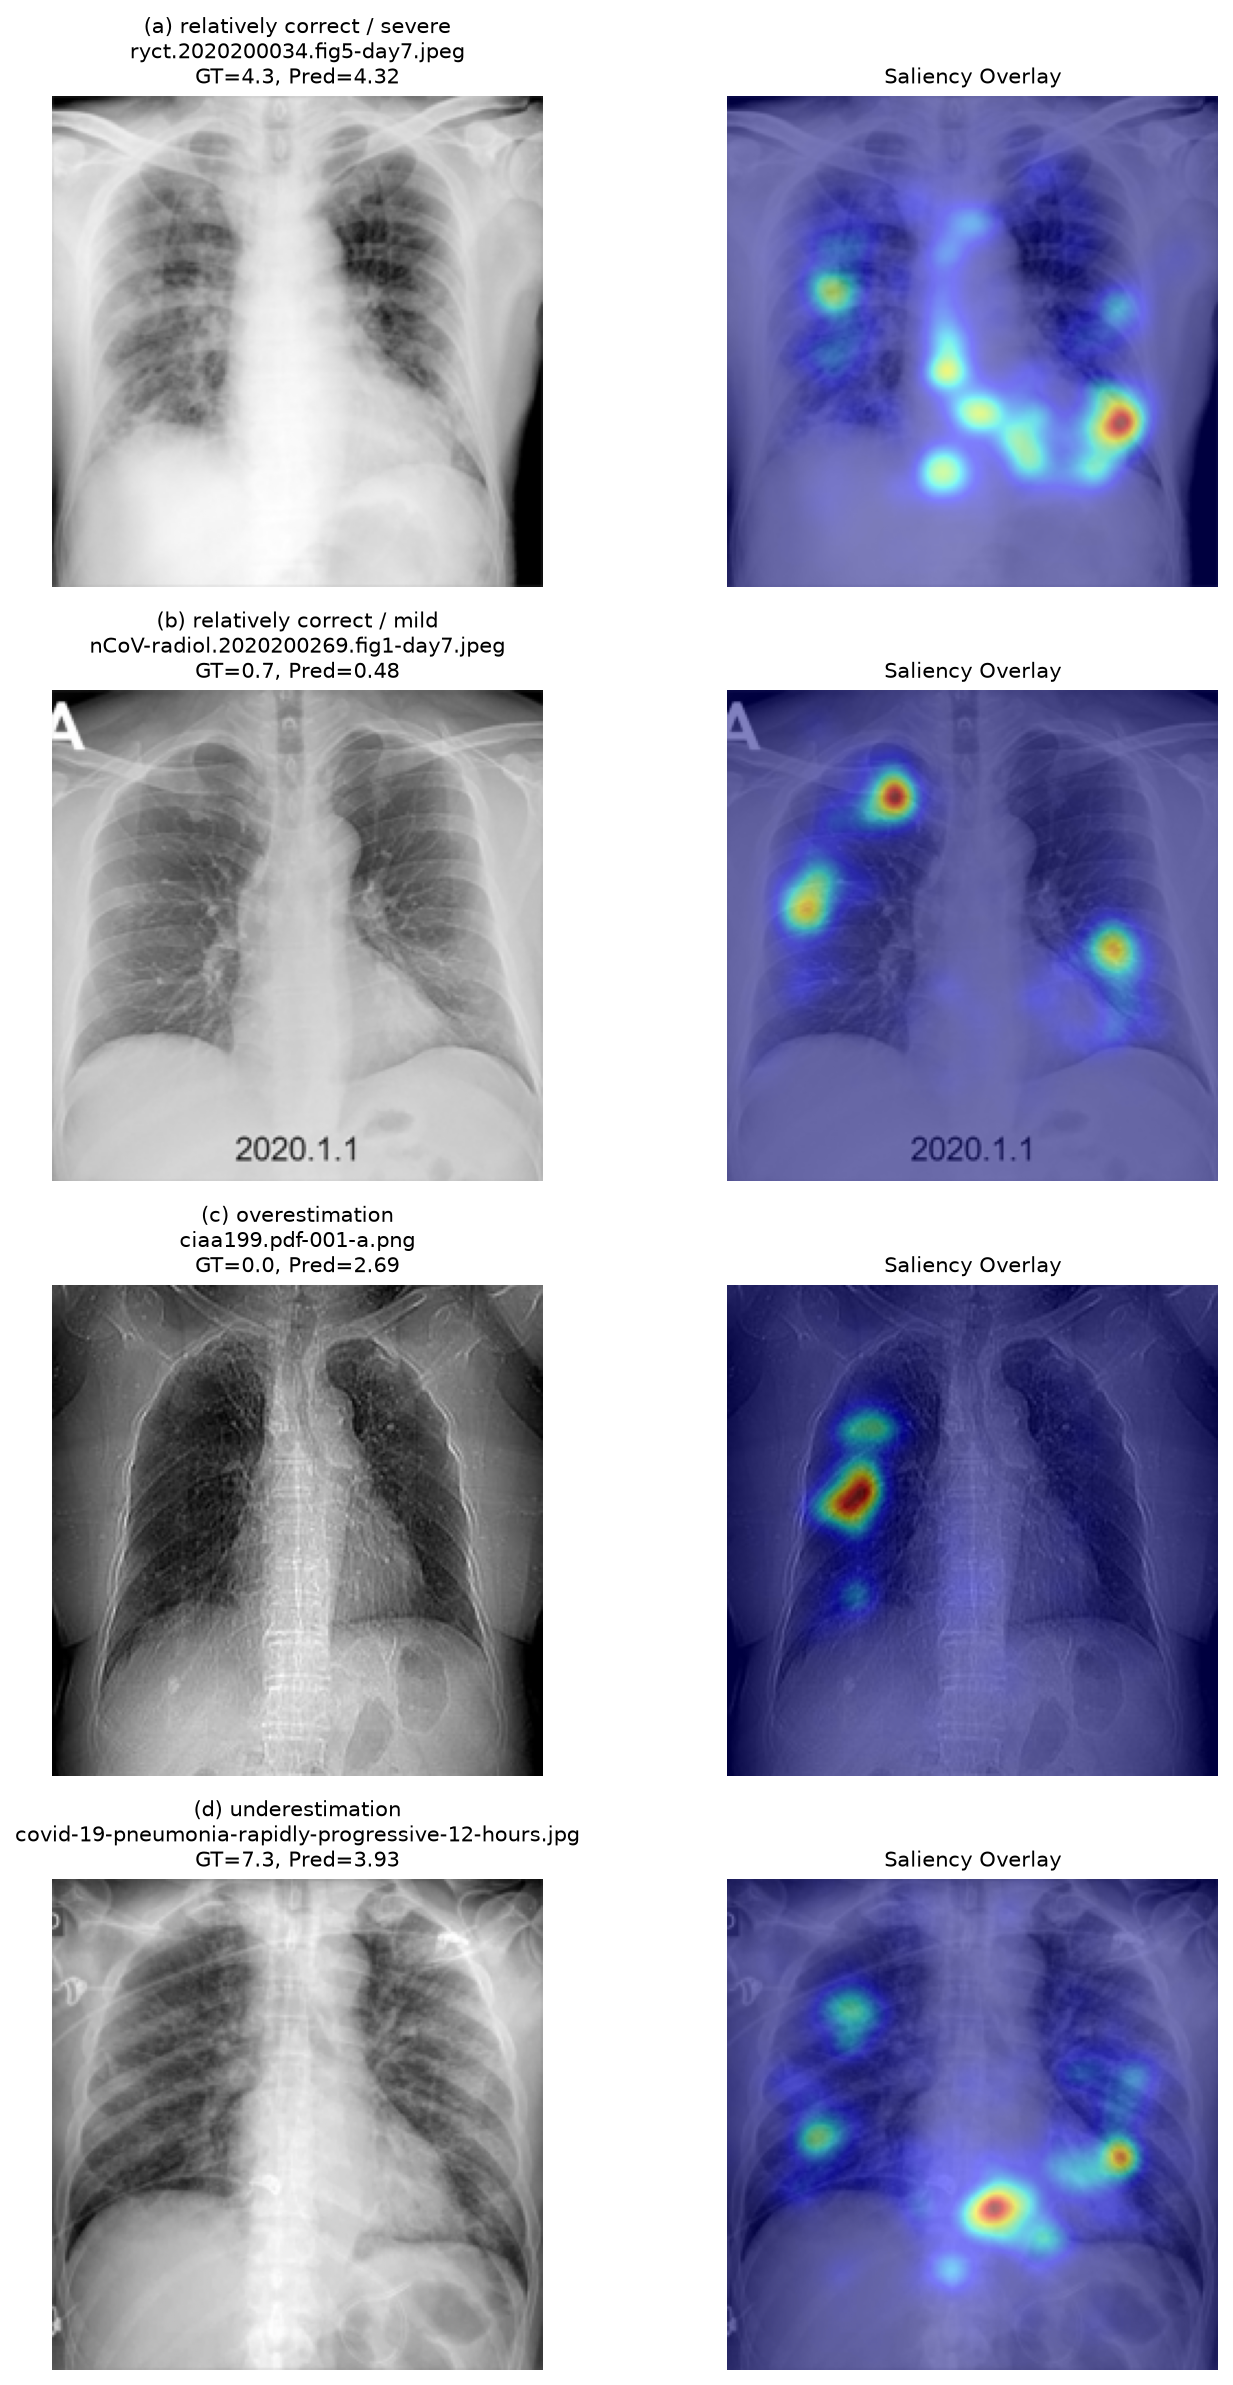

Figure 4 reproduction saved successfully!


In [24]:
#Figure 4 的代码
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit

# ---------------------------
# 1. 重新准备测试集预测结果
# ---------------------------
preds_94 = np.load("duong_d_preds_94.npy")
meta_94 = pd.read_csv("duong_scored_metadata_94.csv")

opacity_idx = xrv.datasets.default_pathologies.index("Lung Opacity")

X = preds_94[:, [opacity_idx]]
y = meta_94["geographic_mean"].astype(float).to_numpy()
groups = meta_94["patientid"]

splitter = GroupShuffleSplit(
    train_size=0.5,
    test_size=0.5,
    random_state=0
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

geo_model = LinearRegression()
geo_model.fit(X[train_idx], y[train_idx])

y_true = y[test_idx]
y_pred = geo_model.predict(X[test_idx])
errors = y_pred - y_true
abs_errors = np.abs(errors)

test_df = pd.DataFrame({
    "global_idx": test_idx,
    "filename": meta_94.iloc[test_idx]["filename"].values,
    "ground_truth": y_true,
    "prediction": y_pred,
    "error": errors,
    "abs_error": abs_errors
}).reset_index(drop=True)

print("Test set size:", len(test_df))

# ---------------------------
# 2. 自动选4个代表样本
# ---------------------------

# (a) 严重且预测较好：GT高，误差小
cand_a = test_df[test_df["ground_truth"] >= 4].sort_values(
    ["abs_error", "ground_truth"], ascending=[True, False]
).iloc[0]

# (b) 轻症且预测较好：GT低，误差小
cand_b = test_df[test_df["ground_truth"] <= 1].sort_values(
    ["abs_error", "ground_truth"], ascending=[True, True]
).iloc[0]

# (c) 明显高估：GT低，但预测偏高最多
cand_c = test_df[test_df["ground_truth"] <= 2].sort_values(
    "error", ascending=False
).iloc[0]

# (d) 明显低估：GT高，但预测偏低最多
cand_d = test_df[test_df["ground_truth"] >= 4].sort_values(
    "error", ascending=True
).iloc[0]

selected_cases = [
    ("(a) relatively correct / severe", cand_a),
    ("(b) relatively correct / mild", cand_b),
    ("(c) overestimation", cand_c),
    ("(d) underestimation", cand_d),
]

selected_df = pd.DataFrame([
    {
        "Case": name,
        "filename": row["filename"],
        "ground_truth": row["ground_truth"],
        "prediction": row["prediction"],
        "error": row["error"]
    }
    for name, row in selected_cases
])

display(selected_df)

# ---------------------------
# 3. 定义 saliency 计算函数
# ---------------------------
def make_saliency_for_idx(global_idx):
    sample = scored_dataset[int(global_idx)]
    img = sample["img"]

    x = torch.as_tensor(img, dtype=torch.float32).unsqueeze(0).clone().detach()
    x.requires_grad_(True)

    nn_model.eval()
    nn_model.zero_grad()

    outputs = nn_model(x)
    lung_opacity = outputs[:, opacity_idx]

    theta = float(geo_model.coef_[0])
    bias = float(geo_model.intercept_)

    predicted_extent = theta * lung_opacity + bias

    grads = torch.autograd.grad(predicted_extent.sum(), x)[0][0, 0].detach().cpu().numpy()

    saliency = gaussian(grads**2, sigma=(5, 5), truncate=3.5)

    return img[0], saliency, predicted_extent.item()

# ---------------------------
# 4. 画 Figure 4
# ---------------------------
fig, axes = plt.subplots(4, 2, figsize=(10, 16), dpi=150)

for row_idx, (case_name, row) in enumerate(selected_cases):
    global_idx = int(row["global_idx"])
    img, saliency, pred_val = make_saliency_for_idx(global_idx)

    gt_val = float(row["ground_truth"])
    filename = row["filename"]

    # 左边：原图
    axes[row_idx, 0].imshow(img, cmap="gray")
    axes[row_idx, 0].set_title(
        f"{case_name}\n{filename}\nGT={gt_val:.1f}, Pred={pred_val:.2f}",
        fontsize=10
    )
    axes[row_idx, 0].axis("off")

    # 右边：overlay
    axes[row_idx, 1].imshow(img, cmap="gray")
    axes[row_idx, 1].imshow(
        saliency,
        cmap="jet",
        alpha=0.5,
        vmin=0,
        vmax=saliency.max()
    )
    axes[row_idx, 1].set_title("Saliency Overlay", fontsize=10)
    axes[row_idx, 1].axis("off")

plt.tight_layout()

plt.savefig(
    "Duong_Figure4_Reproduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Duong_Figure4_Reproduction.pdf",
    bbox_inches="tight"
)

plt.show()

selected_df.to_csv(
    "Duong_Figure4_SelectedCases.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Figure 4 reproduction saved successfully!")